In [2]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# EDIT THIS if your collector output is elsewhere. This can also be the exact
# codex_activity/exports/<timestamp> directory containing the CSVs.
DATA_ROOT = Path("/Users/yoanayosifova/Desktop/codex-health/process_metrics/codex_activity")
GRAIN = "week"                  # "week" or "month"
RETURN_DAYS = 30                # exploratory fixed follow-up, not a validated threshold
RESPONSE_DAYS = 7               # compare issues with the same opportunity for a reply
TOP_N = 15
CI_WORKFLOW_IDS = None          # e.g. [12345, 67890] AFTER inspecting workflow_inventory below
SAVE_OUTPUTS = False            # True saves tables/figures into a NEW local analysis folder

KINDS = ["commit", "issue_opened", "pr_opened"]
LABELS = ["other_user", "bot", "unknown"]
RESPONSE_CLASSES = ["any", "other_user", "bot", "unknown"]
NAMES = {"other_user": "Other users (not identified as bots)", "bot": "Bots", "unknown": "Unknown",
         "any": "Any responder"}
COLORS = {"other_user": "#2166ac", "bot": "#d97706", "unknown": "#777777", "any": "#15803d"}
ACTIVITY_NAMES = {"commit": "Commits", "issue_opened": "Issues opened", "pr_opened": "PRs opened"}
ACTIVITY_COLORS = ["#2166ac", "#009e73", "#cc79a7"]
if GRAIN not in ("week", "month") or RETURN_DAYS <= 0 or RESPONSE_DAYS <= 0:
    raise ValueError("Check GRAIN and positive follow-up days")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .15, "font.size": 10, "figure.dpi": 110})

## 1. Load and check the export
This cell refuses incomplete downloads so missing records are not plotted as zero. Fix gaps with the collector first. API-visible completeness still cannot recover deleted/inaccessible history. The export's `manifest.json` and retrieval timestamps remain the source of scope information.

In [3]:
def resolve_export(root):
    root = root.expanduser()
    if (root / "manifest.json").exists():
        return root
    pointer = root / "latest.json"
    if pointer.exists():
        original = Path(json.loads(pointer.read_text())["export_directory"])
        # Prefer the copy beneath DATA_ROOT if the whole output folder was moved.
        for candidate in (root / "exports" / original.name, original):
            if (candidate / "manifest.json").exists():
                return candidate
    raise FileNotFoundError(f"No completed export found in {root}. Wait for collection to finish, or set DATA_ROOT to an export directory.")

EXPORT = resolve_export(DATA_ROOT)
manifest = json.loads((EXPORT / "manifest.json").read_text())
START = pd.Timestamp(manifest["scope"]["start"])
END = pd.Timestamp(manifest["scope"]["end"])
print("Export:", EXPORT)
print("Window:", START, "to", END, "(end exclusive)")
print("Page retrieval range:", manifest.get("page_retrieval_earliest"), "to", manifest.get("page_retrieval_latest"))
if manifest.get("gaps") or manifest.get("collection_status") != "complete_for_api_visible_scope":
    display(pd.DataFrame(manifest.get("gaps", [])))
    raise ValueError("Incomplete collection. Repair the gaps before interpreting plots.")

OUTPUT = EXPORT / ("analysis_" + pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ"))
if SAVE_OUTPUTS:
    OUTPUT.mkdir(parents=True, exist_ok=False)

def load_csv(name, dates=(), numbers=()):
    frame = pd.read_csv(EXPORT / name, dtype="string", keep_default_na=False)
    for col in dates:
        frame[col] = pd.to_datetime(frame[col].replace("", pd.NA), utc=True, errors="raise")
    for col in numbers:
        frame[col] = pd.to_numeric(frame[col].replace("", pd.NA), errors="raise").astype(float)
    if "data_complete" in frame and not frame["data_complete"].str.lower().eq("true").all():
        raise ValueError(f"{name} contains incomplete results")
    return frame

activities = load_csv("activities.csv", dates=["created_at"])
contributors = load_csv("contributors_all.csv", dates=["first_activity", "last_activity"],
                        numbers=KINDS + ["total_contributions"])
responses = load_csv("issue_responses.csv", dates=["opened_at", "responded_at"],
                     numbers=["response_hours", "follow_up_hours"])
runs = load_csv("workflow_runs.csv", dates=["created_at", "retrieved_at"], numbers=["run_attempt"])

for frame, key in [(activities, ["activity_type", "activity_id"]), (contributors, ["account_id"]),
                   (responses, ["issue_id", "response_class"]), (runs, ["run_id"])]:
    if frame.duplicated(key).any():
        raise ValueError(f"Duplicate records for {key}; inspect before analysing")
for frame, col in [(activities,"created_at"), (responses,"opened_at"), (runs,"created_at")]:
    if not frame[col].between(START, END, inclusive="left").all():
        raise ValueError(f"Out-of-window dates in {col}")
if not responses["response_class"].isin(RESPONSE_CLASSES).all():
    raise ValueError("Unexpected response classes")
if not responses.groupby("issue_id")["response_class"].nunique().eq(4).all():
    raise ValueError("Expected four response-class rows per issue")
observed_mask = responses["response_status"].eq("observed")
if (responses.loc[observed_mask, "response_hours"].isna().any()
    or responses.loc[observed_mask, "response_hours"].lt(0).any()
    or not responses.loc[observed_mask, "responded_at"].lt(END).all()):
    raise ValueError("Invalid observed response timestamps/durations")
if not runs["event"].isin(["push", "pull_request"]).all():
    raise ValueError("Unexpected workflow event")

print(f"Loaded {len(activities):,} contributions, {len(contributors):,} identified accounts, "
      f"{responses['issue_id'].nunique():,} issues and {len(runs):,} workflow runs.")
print("Unknown/unattributed contributions:", activities["account_label"].eq("unknown").sum())

Export: /Users/yoanayosifova/Desktop/codex-health/process_metrics/codex_activity/exports/20261023T050449-97395000
Window: 2025-10-22 00:00:00+00:00 to 2026-10-21 00:00:00+00:00 (end exclusive)
Page retrieval range: 2026-10-23T00:13:12Z to 2026-10-23T05:04:49Z
Loaded 59,740 contributions, 25,887 identified accounts, 33,964 issues and 446,615 workflow runs.
Unknown/unattributed contributions: 25


In [4]:
# Common date/plot helpers: weeks start Monday UTC; months start on day 1.
def period_of(series, grain):
    naive = series.dt.tz_convert("UTC").dt.tz_localize(None)
    frequency = "W-SUN" if grain == "week" else "M"
    return naive.dt.to_period(frequency).dt.start_time.dt.tz_localize("UTC")

def calendar(grain):
    first = period_of(pd.Series([START]), grain).iloc[0]
    last = period_of(pd.Series([END - pd.Timedelta(nanoseconds=1)]), grain).iloc[0]
    index = pd.date_range(first, last, freq="W-MON" if grain == "week" else "MS", name="period_start")
    nxt = index + (pd.offsets.Week() if grain == "week" else pd.offsets.MonthBegin())
    result = pd.DataFrame({"period_start": index, "period_end": nxt})
    result["observed_start"] = result["period_start"].where(result["period_start"].ge(START), START)
    result["observed_end"] = result["period_end"].where(result["period_end"].le(END), END)
    result["exposure_days"] = (result["observed_end"] - result["observed_start"]).dt.total_seconds()/86400
    result["partial_period"] = result["period_start"].lt(START) | result["period_end"].gt(END)
    return result.set_index("period_start")

CALENDARS = {g: calendar(g) for g in ("week", "month")}

def time_axis(ax, grain=GRAIN):
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=9))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y", tz=START.tz))
    cal = CALENDARS[grain]
    for p, row in cal.loc[cal["partial_period"]].iterrows():
        ax.axvspan(p, row["observed_end"], color="#888888", alpha=.12)
    ax.set_xlim(cal.index[0].to_pydatetime(), END.to_pydatetime())
    ax.set_xlabel("UTC; shaded periods are partial")

def finish(fig, name):
    fig.tight_layout()
    if SAVE_OUTPUTS:
        fig.savefig(OUTPUT / f"{name}_{GRAIN}.png", dpi=180, bbox_inches="tight")
    plt.show()

def save_table(frame, name, index=False):
    if SAVE_OUTPUTS:
        frame.to_csv(OUTPUT / f"{name}.csv", index=index)

def ratio(numerator, denominator):
    return 100 * numerator / denominator.replace(0, np.nan)

## 2. Who contributes more than once?
The full table below includes account IDs, labels, activity counts and totals. `repeat_contributors` contains **all** qualifying accounts; display may truncate long tables. The top-15 chart is only a readable subset.

The summary distinguishes **two or more contributions** from **activity on multiple dates/weeks**. The latter is closer to sustained participation. Counts from different activity types need not have equal effort or value.

In [17]:
known = activities.loc[activities["account_id"].ne("") & activities["account_label"].isin(["bot", "other_user"])].copy()
known = known.sort_values(["created_at", "activity_type", "activity_id"])
known["active_day"] = known["created_at"].dt.normalize()
known["active_week"] = period_of(known["created_at"], "week")
known["active_month"] = period_of(known["created_at"], "month")
known["gap_days"] = known.groupby("account_id")["created_at"].diff().dt.total_seconds()/86400
extras = known.groupby("account_id").agg(active_days=("active_day","nunique"),
    active_weeks=("active_week","nunique"), active_months=("active_month","nunique"),
    mean_gap_days=("gap_days","mean"))
contributor_analysis = contributors.merge(extras, left_on="account_id", right_index=True, how="left", validate="one_to_one")
contributor_analysis["days_since_first_observed"] = (END - contributor_analysis["first_activity"]).dt.total_seconds()/86400
contributor_analysis["days_since_latest_observed"] = (END - contributor_analysis["last_activity"]).dt.total_seconds()/86400
contributor_analysis["more_than_one"] = contributor_analysis["total_contributions"].gt(1)
contributor_analysis["active_on_multiple_days"] = contributor_analysis["active_days"].gt(1)
contributor_analysis["active_in_multiple_weeks"] = contributor_analysis["active_weeks"].gt(1)
repeat_contributors = contributor_analysis.loc[contributor_analysis["more_than_one"]].sort_values("total_contributions", ascending=False)
display(repeat_contributors[["account_id", "login", "account_label", *KINDS, "total_contributions",
    "active_days", "active_weeks", "active_months", "mean_gap_days", "days_since_latest_observed"]])
save_table(repeat_contributors, "repeat_contributors")
save_table(contributor_analysis, "all_contributor_metrics")

repeat_summary = contributor_analysis.groupby("account_label").agg(
    all_accounts=("account_id","size"), repeat_accounts=("more_than_one","sum"),
    multiple_day_accounts=("active_on_multiple_days","sum"), multiple_week_accounts=("active_in_multiple_weeks","sum"))
repeat_summary["repeat_share_pct"] = ratio(repeat_summary["repeat_accounts"], repeat_summary["all_accounts"])
display(repeat_summary)
save_table(repeat_summary, "repeat_summary", index=True)

,account_id,login,account_label,commit,issue_opened,pr_opened,total_contributions,active_days,active_weeks,active_months,mean_gap_days,days_since_latest_observed
0,240088373,copyberry[bot],bot,0.0,0.0,4258.0,4258.0,102,16,4,0.024103,0.012222
1,230027070,jif-oai,other_user,1846.0,0.0,1331.0,3177.0,251,49,13,0.114463,0.022535
2,223546144,etraut-openai,other_user,953.0,6.0,596.0,1555.0,271,53,13,0.233584,0.096875
3,655869,bolinfest,other_user,622.0,0.0,804.0,1426.0,182,41,12,0.253144,0.315949
4,219906144,aibrahim-oai,other_user,485.0,0.0,724.0,1209.0,207,46,13,0.295625,6.120347
...,...,...,...,...,...,...,...,...,...,...,...,...
2627,20948549,suosui,other_user,0.0,2.0,0.0,2.0,1,1,1,0.014167,228.593484
2628,20956142,pioner22,other_user,0.0,2.0,0.0,2.0,2,2,2,13.551262,6.626551
2629,209693375,charleschen-oai,other_user,1.0,0.0,1.0,2.0,2,2,2,61.681528,96.186505
2630,209693410,cpaasch-oai,other_user,1.0,0.0,1.0,2.0,2,1,1,1.847720,167.174155


,all_accounts,repeat_accounts,multiple_day_accounts,multiple_week_accounts,repeat_share_pct
account_label,,,,,
bot,11,6,5,4,54.545455
other_user,25876,4256,3585,3230,16.447674


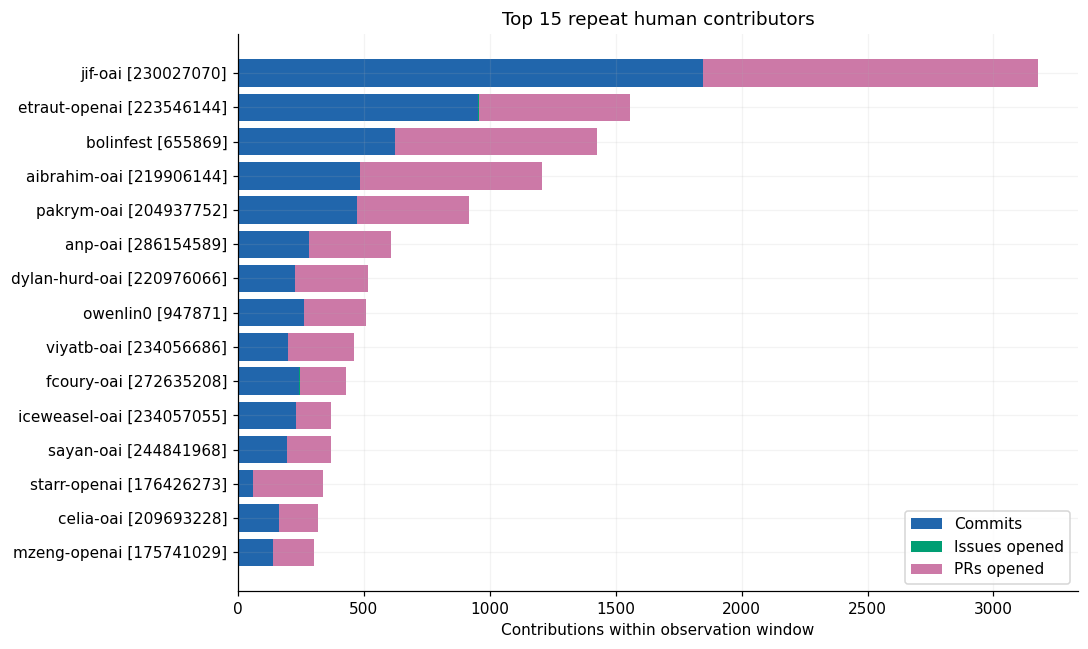

In [19]:
top = (
    repeat_contributors.loc[
        repeat_contributors["account_label"].eq("other_user")
    ]
    .sort_values("total_contributions", ascending=False)
    .head(TOP_N)
    .iloc[::-1]
)

fig, ax = plt.subplots(figsize=(10, 6))
names = top["login"] + " [" + top["account_id"].astype(str) + "]"
left = np.zeros(len(top))

for kind, color in zip(KINDS, ACTIVITY_COLORS):
    counts = top[kind].to_numpy(dtype=float, na_value=np.nan)
    ax.barh(
        names, counts, left=left,
        label=ACTIVITY_NAMES[kind], color=color
    )
    left += counts

ax.set_title(f"Top {len(top)} repeat human contributors")
ax.set_xlabel("Contributions within observation window")
ax.legend()
finish(fig, "top_repeat_contributors_other_users")

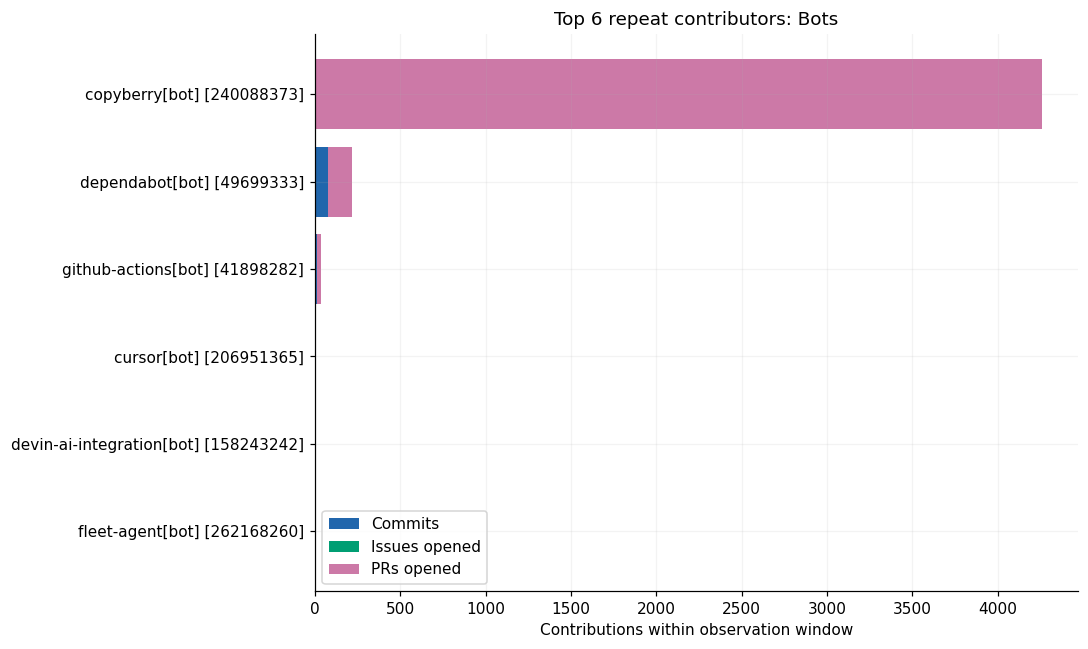

In [12]:
top = (
    repeat_contributors.loc[
        repeat_contributors["account_label"].eq("bot")
    ]
    .sort_values("total_contributions", ascending=False)
    .head(TOP_N)
    .iloc[::-1]
)

fig, ax = plt.subplots(figsize=(10, 6))
names = top["login"] + " [" + top["account_id"].astype(str) + "]"
left = np.zeros(len(top))

for kind, color in zip(KINDS, ACTIVITY_COLORS):
    counts = top[kind].to_numpy(dtype=float, na_value=np.nan)
    ax.barh(
        names, counts, left=left,
        label=ACTIVITY_NAMES[kind], color=color
    )
    left += counts

ax.set_title(f"Top {len(top)} repeat contributors: Bots")
ax.set_xlabel("Contributions within observation window")
ax.legend()
finish(fig, "top_repeat_contributors_bots")

## 3. How quickly are issues answered?

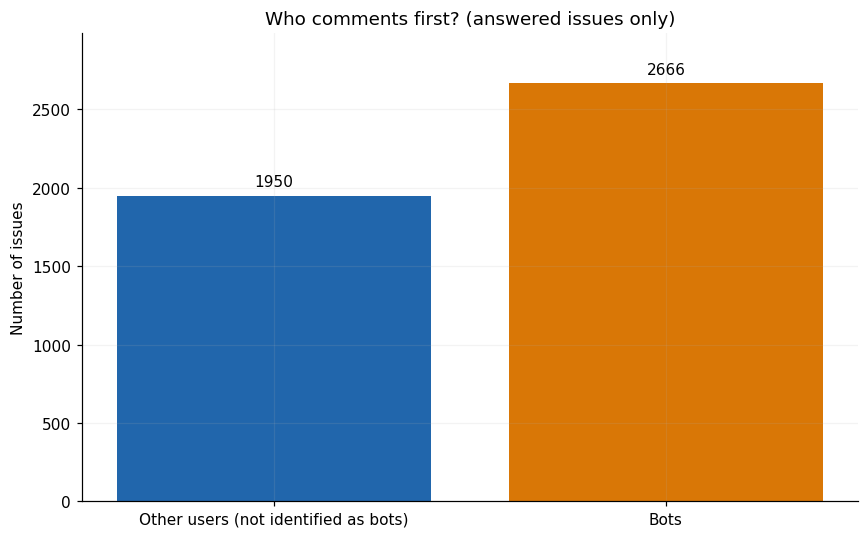

In [ ]:
first_responder = (
    responses.loc[
        responses["response_class"].eq("any")
        & responses["response_status"].eq("observed"),
        "responder_label"
    ]
    .value_counts()
    .reindex(["other_user", "bot"], fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Other users (not identified as bots)", "Bots"],
    first_responder.to_numpy(dtype=float),
    color=["#2166ac", "#d97706"]
)

ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set_title("Who comments first? (answered issues only)")
ax.set_ylabel("Number of issues")
ax.set_ylim(0, max(first_responder.max(), 1) * 1.12)

plt.tight_layout()
plt.show()

## 4. What happens to workflow runs?
First inspect the workflow inventory. The export includes all workflows for the selected trigger events: tests, builds, deployment, housekeeping, etc. To discuss CI/code checks specifically, set `CI_WORKFLOW_IDS` in the configuration cell after inspecting which workflows implement those checks, then rerun. It is unsafe to assume every Actions run tests code quality.

- **Status** describes state (`queued`, `in_progress`, `completed`, ...).
- **Conclusion** describes outcome (`success`, `failure`, `cancelled`, ...). A completed run may fail.
- `none` means no recorded conclusion; retain it instead of silently dropping unfinished runs.
- Rates below show both **success / all runs** and **success / (success + failure)**. The latter excludes cancellations and other outcomes; neither is a percentage of commits/PRs that are “good”.
- Reruns share a run ID; the export stores the latest attempt representation. These are not first-attempt pass rates.

runs  \
event        workflow_id workflow_name                                 
pull_request 193775875   sdk                                   59633   
             156554548   ci                                    59632   
             158138315   rust-ci                               59625   
             209257462   cargo-deny                            56387   
             161544154   Codespell                             42592   
...                                                              ...   
push         252759966   rust-ci-full arm64-shards-2               1   
             261491306   Test Manager internal runner probe        1   
             261490060   Test Manager probe                        1   
             257002891   One-off Codex CLI macOS Notarization      1   
pull_request 300519238   app-server-protocol-compatibility         1   

                                                                              first_run  \
event        workflow_id workflow_name                                                    
pull_request 193775875   sdk                                  2025-10-22 02:54:46+00:00   
             156554548   ci                                   2025-10-22 02:54:46+00:00   
             158138315   rust-ci                              2025-10-22 02:54:46+00:00   
             209257462   cargo-deny                           2025-11-21 21:45:33+00:00   
             161544154   Codespell                            2025-10-22 02:54:46+00:00   
...                                                                                 ...   
push         252759966   rust-ci-full arm64-shards-2          2026-05-08 00:11:33+00:00   
             261491306   Test Manager internal runner probe   2026-04-15 21:39:07+00:00   
             261490060   Test Manager probe                   2026-04-15 21:34:59+00:00   
             257002891   One-off Codex CLI macOS Notarization 2026-04-08 22:11:46+00:00   
pull_request 300519238   app-server-protocol-compatibility    2026-06-23 00:30:06+00:00   

                                                                             latest_run  
event        workflow_id workflow_name                                                   
pull_request 193775875   sdk                                  2026-07-10 01:33:47+00:00  
             156554548   ci                                   2026-07-10 01:33:47+00:00  
             158138315   rust-ci                              2026-07-10 01:33:47+00:00  
             209257462   cargo-deny                           2026-07-10 01:33:47+00:00  
             161544154   Codespell                            2026-06-26 22:03:39+00:00  
...                                                                                 ...  
push         252759966   rust-ci-full arm64-shards-2          2026-05-08 00:11:33+00:00  
             261491306   Test Manager internal runner probe   2026-04-15 21:39:07+00:00  
             261490060   Test Manager probe                   2026-04-15 21:34:59+00:00  
             257002891   One-off Codex CLI macOS Notarization 2026-04-08 22:11:46+00:00  
pull_request 300519238   app-server-protocol-compatibility    2026-06-23 00:30:06+00:00  

[67 rows x 3 columns]

All exported workflows | 446615 unique run IDs
Run IDs with run_attempt > 1: 9371


status,queued,in_progress,completed,waiting,pending,requested
event,,,,,,
push,0,0,48139,0,0,0
pull_request,31,0,398445,0,0,0


conclusion,success,failure,cancelled,timed_out,skipped,action_required,stale,neutral,none,startup_failure
event,,,,,,,,,,
push,31708,15817,612,0,0,0,0,0,0,2
pull_request,314412,56329,27687,0,4,0,0,0,31,13


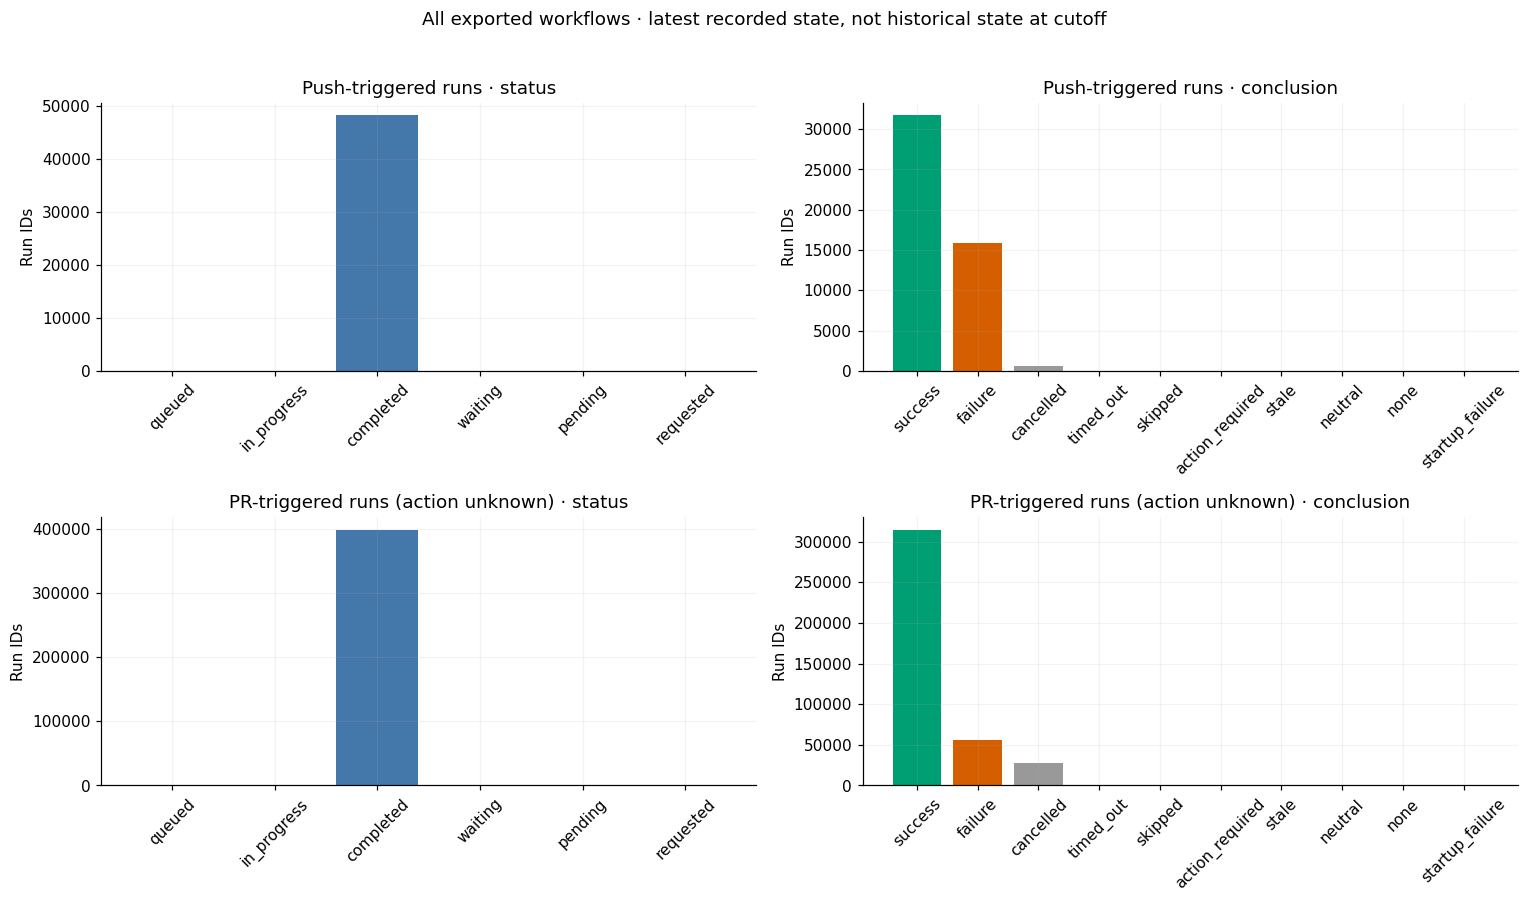

In [7]:
STATUS_ORDER = ["queued", "in_progress", "completed", "waiting", "pending", "requested"]
CONCLUSION_ORDER = ["success", "failure", "cancelled", "timed_out", "skipped", "action_required", "stale", "neutral", "none"]
OUTCOME_COLORS = {"success":"#009e73", "failure":"#d55e00", "cancelled":"#999999", "timed_out":"#e69f00",
                  "skipped":"#56b4e9", "action_required":"#cc79a7", "stale":"#8c564b", "neutral":"#7777bb", "none":"#d6d6d6"}
EVENT_NAMES = {"push": "Push-triggered runs", "pull_request": "PR-triggered runs (action unknown)"}
runs["conclusion"] = runs["conclusion"].replace("", "none")
runs["status"] = runs["status"].replace("", "unknown")
workflow_inventory = runs.groupby(["event", "workflow_id", "workflow_name"], dropna=False).agg(
    runs=("run_id","size"), first_run=("created_at","min"), latest_run=("created_at","max"))
display(workflow_inventory.sort_values("runs", ascending=False))
workflow_data = runs.copy()
if CI_WORKFLOW_IDS is not None:
    workflow_data = runs.loc[runs["workflow_id"].isin([str(x) for x in CI_WORKFLOW_IDS])].copy()
    if workflow_data.empty:
        raise ValueError("Selected workflow IDs match no runs")
SCOPE_LABEL = "All exported workflows" if CI_WORKFLOW_IDS is None else "Selected workflows"
print(SCOPE_LABEL, "|", len(workflow_data), "unique run IDs")
print("Run IDs with run_attempt > 1:", workflow_data["run_attempt"].gt(1).sum())

status_values = STATUS_ORDER + sorted(set(workflow_data["status"]) - set(STATUS_ORDER))
conclusion_values = CONCLUSION_ORDER + sorted(set(workflow_data["conclusion"]) - set(CONCLUSION_ORDER))
status_totals = pd.crosstab(workflow_data["event"], workflow_data["status"]).reindex(index=EVENT_NAMES, columns=status_values, fill_value=0)
conclusion_totals = pd.crosstab(workflow_data["event"], workflow_data["conclusion"]).reindex(index=EVENT_NAMES, columns=conclusion_values, fill_value=0)
display(status_totals, conclusion_totals)
save_table(status_totals, "workflow_status_totals", index=True)
save_table(conclusion_totals, "workflow_conclusion_totals", index=True)

fig, axes = plt.subplots(2, 2, figsize=(14,8))
for event, axpair in zip(EVENT_NAMES, axes):
    s, c = status_totals.loc[event], conclusion_totals.loc[event]
    axpair[0].bar(s.index, s.values, color="#4477aa")
    axpair[1].bar(c.index, c.values, color=[OUTCOME_COLORS.get(v,"#555555") for v in c.index])
    for ax, dimension in zip(axpair, ["status", "conclusion"]):
        ax.set(title=f"{EVENT_NAMES[event]} · {dimension}", ylabel="Run IDs")
        ax.tick_params(axis="x", labelrotation=45)
fig.suptitle(SCOPE_LABEL + " · latest recorded state, not historical state at cutoff", y=1.02)
finish(fig, "workflow_totals")

In [21]:
# Both weekly and monthly count tables; all named states retained, including zero counts.
# workflow_periods, workflow_rates = {}, {}
# for grain in ("week", "month"):
#     w = workflow_data.assign(period_start=period_of(workflow_data["created_at"],grain))
#     tables = []
#     for dimension, values in [("status",status_values), ("conclusion",conclusion_values)]:
#         idx = pd.MultiIndex.from_product([CALENDARS[grain].index, EVENT_NAMES, values], names=["period_start","event","value"])
#         cnt = w.groupby(["period_start","event",dimension]).size()
#         cnt.index = cnt.index.set_names(["period_start","event","value"])
#         table = cnt.reindex(idx,fill_value=0).rename("count").reset_index()
#         table["dimension"] = dimension
#         tables.append(table)
#     workflow_periods[grain] = pd.concat(tables,ignore_index=True)
#     c = tables[1].pivot(index=["period_start","event"], columns="value", values="count")
#     rate = pd.DataFrame(index=c.index)
#     rate["all_runs"] = c.sum(axis=1)
#     rate["success"] = c["success"]
#     rate["failure"] = c["failure"]
#     rate["success_plus_failure"] = c["success"] + c["failure"]
#     rate["success_among_all_pct"] = ratio(c["success"], rate["all_runs"])
#     rate["success_among_success_failure_pct"] = ratio(c["success"],rate["success_plus_failure"])
#     workflow_rates[grain] = rate.reset_index()
#     save_table(workflow_periods[grain], "workflow_counts_" + grain)
#     save_table(workflow_rates[grain], "workflow_rates_" + grain)

# fig, axes = plt.subplots(2, 2, figsize=(14,8), sharex=True)
# for event, axpair in zip(EVENT_NAMES, axes):
#     table = workflow_periods[GRAIN].query("event == @event and dimension == 'conclusion'")
#     wide = table.pivot(index="period_start", columns="value", values="count").reindex(columns=conclusion_values,fill_value=0)
#     axpair[0].stackplot(wide.index, *[wide[c].to_numpy(dtype=float) for c in wide], labels=list(wide),
#                        colors=[OUTCOME_COLORS.get(c,"#555555") for c in wide])
#     axpair[0].set(title=EVENT_NAMES[event], ylabel=f"Runs created per {GRAIN}")
#     r = workflow_rates[GRAIN].query("event == @event")
#     axpair[1].plot(r["period_start"],r["success_among_all_pct"],marker="o",markersize=3,label="success / all runs",color="#2166ac")
#     axpair[1].plot(r["period_start"],r["success_among_success_failure_pct"],marker="o",markersize=3,label="success / (success + failure)",color="#009e73")
#     axpair[1].set(title="Different denominators — inspect both", ylabel="Success share (%)", ylim=(0,105))
#     axpair[1].legend(fontsize=8)
#     for ax in axpair: time_axis(ax)
# axes[0,0].legend(fontsize=7,ncol=3)
# finish(fig, "workflow_outcomes_over_time")

# # Per-workflow table helps reveal changes hidden by aggregate outcome rates.
# by_workflow = workflow_data.groupby(["event","workflow_id","workflow_name","conclusion"]).size().unstack(fill_value=0)
# by_workflow = by_workflow.reindex(columns=conclusion_values,fill_value=0)
# by_workflow["total_runs"] = by_workflow.sum(axis=1)
# by_workflow["decisive_runs"] = by_workflow["success"] + by_workflow["failure"]
# by_workflow["failure_among_success_failure_pct"] = ratio(by_workflow["failure"],by_workflow["decisive_runs"])
# display(by_workflow.sort_values("total_runs",ascending=False))
# save_table(by_workflow, "workflow_breakdown", index=True)

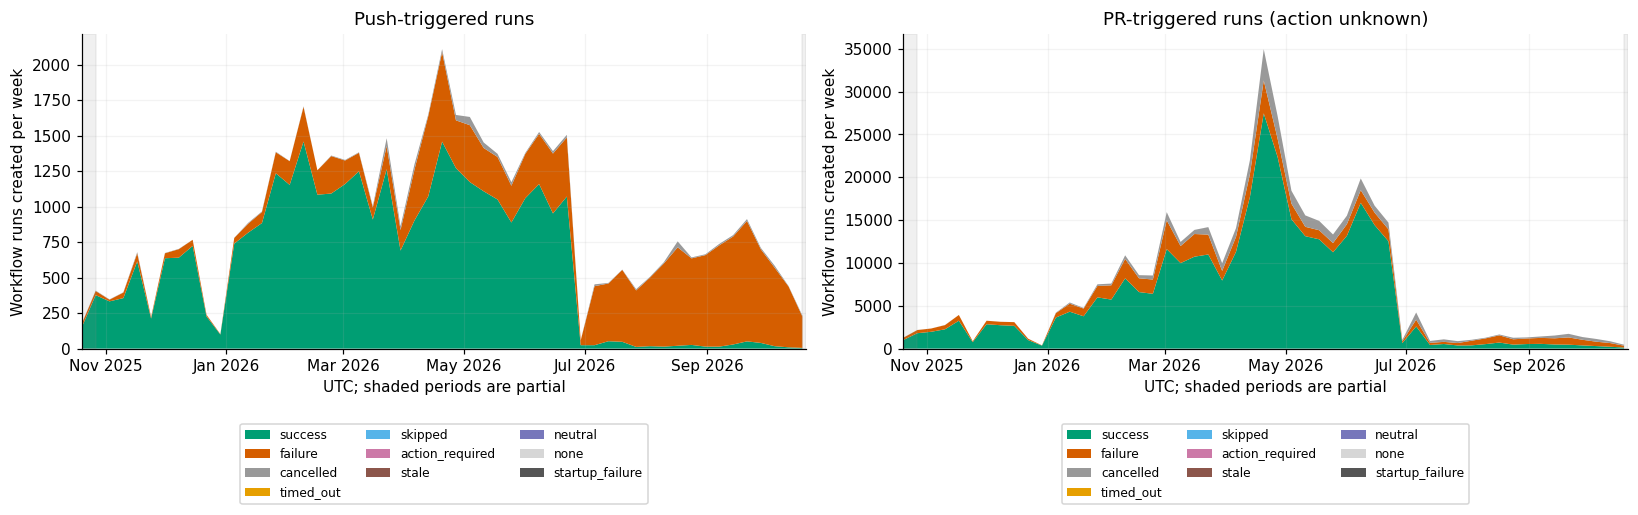

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)

for event, ax in zip(["push", "pull_request"], axes):
    table = workflow_periods[GRAIN].query(
        "event == @event and dimension == 'conclusion'"
    )

    wide = (
        table.pivot(
            index="period_start",
            columns="value",
            values="count"
        )
        .reindex(columns=conclusion_values, fill_value=0)
        .sort_index()
    )

    ax.stackplot(
        wide.index,
        *[
            wide[column].to_numpy(dtype=float, na_value=np.nan)
            for column in wide.columns
        ],
        labels=wide.columns,
        colors=[
            OUTCOME_COLORS.get(column, "#555555")
            for column in wide.columns
        ]
    )

    ax.set_title(EVENT_NAMES[event])
    ax.set_ylabel(f"Workflow runs created per {GRAIN}")
    ax.set_ylim(bottom=0)
    time_axis(ax)

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.22),
        ncol=3,
        fontsize=8
    )

finish(fig, "workflow_outcomes_side_by_side")